# Mesures Manchester Nordic → STM32
Les CSV proviennent uniquement des acquisitions physiques (`collect.py`). Les tests simulés ne sont pas des mesures de débit matériel. Lancer ce notebook depuis `measurements/` ou la racine du projet.

Le payload fixe ne contient ni compteur de séquence ni CRC : les pertes sont **estimées** depuis la durée théorique, sous hypothèse TX continu et paramètres identiques. Le taux d’erreur binaire ci-dessous concerne uniquement les trames complètes, pas les trames rejetées. Une acquisition courte peut inclure une trame partielle aux limites.


In [1]:
from pathlib import Path
import csv
import plotly.graph_objects as go
from plotly.subplots import make_subplots
root = Path.cwd()
if (root / 'measurements').is_dir():
    root = root / 'measurements'
rows = []
for path in sorted(root.glob('*.csv')):
    with path.open() as f:
        for r in csv.DictReader(f):
            if r.get('source') == 'hardware':
                rows.append({k: (int(v) if v.isdigit() else v) for k, v in r.items()})
print(f'{len(rows)} acquisitions physiques')


42 acquisitions physiques


In [2]:
for r in rows:
    expected = r['expected_frames']
    r['loss_estimate_pct'] = 100 * (1 - r['complete_frames'] / expected) if expected else float('nan')
    r['success_pct'] = 100 * r['correct_frames'] / expected if expected else float('nan')
    r['complete_frame_ber'] = r.get('payload_bit_errors', float('nan')) / (24 * r['complete_frames']) if r['complete_frames'] else float('nan')
    r['manchester_errors_s'] = r['manchester_errors'] * 1000 / r['duration_ms']
    r['sample_coverage_pct'] = (100 * r['samples_acquired'] * r['sample_us'] / (1000 * r['duration_ms'])) if r.get('rx_mode', 0) == 0 else None
    print({k: r[k] for k in ['timestamp_utc', 'half_bit_us', 'sample_us', 'goodput_bps', 'loss_estimate_pct', 'success_pct', 'complete_frame_ber', 'sample_coverage_pct']})


{'timestamp_utc': '20261019T085453_530761Z', 'half_bit_us': 48, 'sample_us': 12, 'goodput_bps': 1574, 'loss_estimate_pct': 73.54344466097709, 'success_pct': 26.456555339022916, 'complete_frame_ber': nan, 'sample_coverage_pct': 99.89467508874851}
{'timestamp_utc': '20261019T085646_343256Z', 'half_bit_us': 48, 'sample_us': 12, 'goodput_bps': 47, 'loss_estimate_pct': 99.19354838709677, 'success_pct': 0.8064516129032258, 'complete_frame_ber': 0.0, 'sample_coverage_pct': 99.99140085991401}
{'timestamp_utc': '20261019T085646_343256Z', 'half_bit_us': 48, 'sample_us': 12, 'goodput_bps': 76, 'loss_estimate_pct': 98.70967741935483, 'success_pct': 1.2903225806451613, 'complete_frame_ber': 0.0, 'sample_coverage_pct': 99.99140085991401}
{'timestamp_utc': '20261019T085646_343256Z', 'half_bit_us': 48, 'sample_us': 12, 'goodput_bps': 4, 'loss_estimate_pct': 99.91935483870968, 'success_pct': 0.08064516129032258, 'complete_frame_ber': 0.0, 'sample_coverage_pct': 99.99140085991401}
{'timestamp_utc': '202

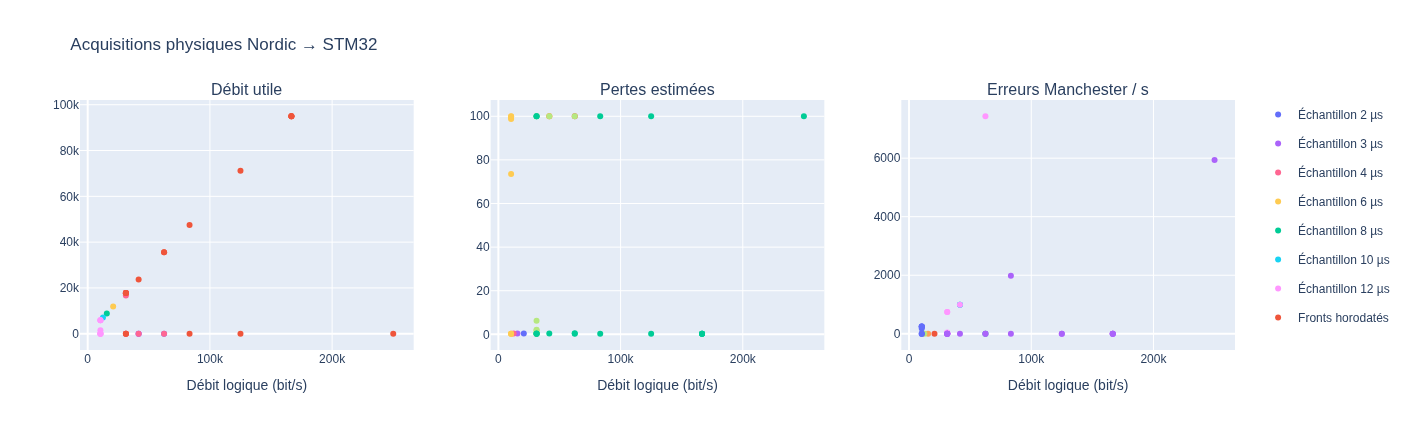

In [5]:
if rows:
    fig = make_subplots(rows=1, cols=3, subplot_titles=['Débit utile', 'Pertes estimées', 'Erreurs Manchester / s'])
    for mode, sample in sorted({(r.get('rx_mode', 0), 0 if r.get('rx_mode', 0) else r['sample_us']) for r in rows}):
        group = sorted([r for r in rows if r.get('rx_mode', 0) == mode and (mode == 1 or r['sample_us'] == sample)], key=lambda r: r['bitrate_bps'])
        for col, key in enumerate(['goodput_bps', 'loss_estimate_pct', 'manchester_errors_s'], 1):
            fig.add_trace(go.Scatter(x=[r['bitrate_bps'] for r in group], y=[r[key] for r in group], mode='markers', name=('Fronts horodatés' if mode else f'Échantillon {sample} µs'), legendgroup=str((mode, sample)), showlegend=col == 1, text=[r.get('label', '') for r in group]), row=1, col=col)
    fig.update_xaxes(title_text='Débit logique (bit/s)')
    fig.update_layout(height=430, title='Acquisitions physiques Nordic → STM32')
    fig.show()
    # fig.write_html(root / 'comparison.html', include_plotlyjs=True)
else:
    print('Aucune mesure : connecter les cartes puis lancer collect.py.')


## Interprétation du réglage retenu
Le profil optimisé utilise les fronts GPIO horodatés (rx_mode=1, sample_us=0), le TX PWM/EasyDMA avec quartz et une interruption RX prioritaire. Les lignes `final_validation_3us` sont les acquisitions longues de validation. Les essais à 2 µs montrent la limite dépassée ; 3 µs correspond au meilleur réglage sans erreur observée pendant la validation, dans les conditions de cette liaison.

Les pertes théoriques incluent le décalage d'horloge RX et les trames aux limites de la fenêtre. Une valeur proche de 0,3 % avec zéro erreur ne prouve pas une perte réelle de 0,3 %. Sans compteur de séquence TX, le nombre exact de trames perdues n'est pas disponible.


3 validations, 180.000 s, 712281 trames correctes, 94970.8 bit/s utiles
{'incorrect_frames': 0, 'manchester_errors': 0, 'preamble_errors': 0, 'sfd_errors': 0, 'gpio_errors': 0, 'payload_bit_errors': 0}


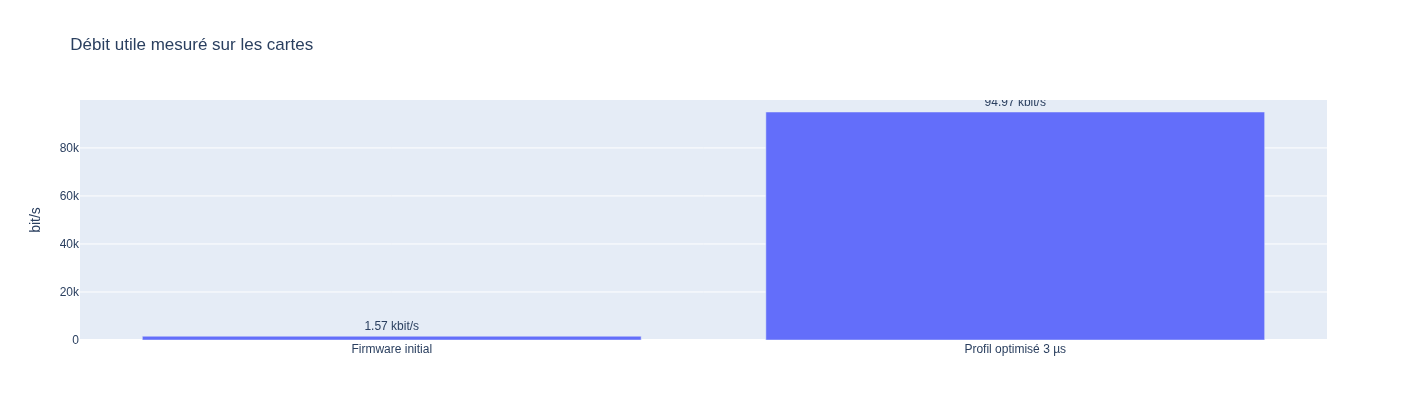

In [6]:
baseline = [r for r in rows if r.get('label') == 'initial_firmware']
validated = [r for r in rows if r.get('label') == 'final_validation_3us']
if validated:
    frames = sum(r['correct_frames'] for r in validated)
    duration_s = sum(r['duration_ms'] for r in validated) / 1000
    errors = {key: sum(r.get(key, 0) for r in validated) for key in ['incorrect_frames', 'manchester_errors', 'preamble_errors', 'sfd_errors', 'gpio_errors', 'payload_bit_errors']}
    print(f'{len(validated)} validations, {duration_s:.3f} s, {frames} trames correctes, {24 * frames / duration_s:.1f} bit/s utiles')
    print(errors)
    labels, rates = [], []
    for label, group in [('Firmware initial', baseline), ('Profil optimisé 3 µs', validated)]:
        if group:
            labels.append(label)
            rates.append(sum(r['correct_frames'] for r in group) * 24000 / sum(r['duration_ms'] for r in group))
    fig = go.Figure(go.Bar(x=labels, y=rates, text=[f'{v / 1000:.2f} kbit/s' for v in rates], textposition='outside'))
    fig.update_layout(title='Débit utile mesuré sur les cartes', yaxis_title='bit/s', height=420)
    fig.show()
    # fig.write_html(root / 'validation.html', include_plotlyjs=True)
else:
    print('Validation longue en cours ; relancer après les acquisitions.')
